In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/nilotpaldhar/global-superstore-2016/global_superstore_2016.xlsx


In [2]:
import pandas as pd

In [3]:
df = pd.read_excel(r"/kaggle/input/datasets/nilotpaldhar/global-superstore-2016/global_superstore_2016.xlsx")

In [4]:
df.head(1)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Postal Code,City,...,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Shipping Cost,Order Priority
0,40098,CA-2014-AB10015140-41954,2014-11-11,2014-11-13,First Class,AB-100151402,Aaron Bergman,Consumer,73120.0,Oklahoma City,...,TEC-PH-5816,Technology,Phones,Samsung Convoy 3,221.98,2,0.0,62.1544,40.77,High


In [5]:
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Postal Code', 'City',
       'State', 'Country', 'Region', 'Market', 'Product ID', 'Category',
       'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount',
       'Profit', 'Shipping Cost', 'Order Priority'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 24 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Row ID          51290 non-null  int64         
 1   Order ID        51290 non-null  object        
 2   Order Date      51290 non-null  datetime64[ns]
 3   Ship Date       51290 non-null  datetime64[ns]
 4   Ship Mode       51290 non-null  object        
 5   Customer ID     51290 non-null  object        
 6   Customer Name   51290 non-null  object        
 7   Segment         51290 non-null  object        
 8   Postal Code     9994 non-null   float64       
 9   City            51290 non-null  object        
 10  State           51290 non-null  object        
 11  Country         51290 non-null  object        
 12  Region          51290 non-null  object        
 13  Market          51290 non-null  object        
 14  Product ID      51290 non-null  object        
 15  Ca

In [7]:
df.isnull().sum()

Row ID                0
Order ID              0
Order Date            0
Ship Date             0
Ship Mode             0
Customer ID           0
Customer Name         0
Segment               0
Postal Code       41296
City                  0
State                 0
Country               0
Region                0
Market                0
Product ID            0
Category              0
Sub-Category          0
Product Name          0
Sales                 0
Quantity              0
Discount              0
Profit                0
Shipping Cost         0
Order Priority        0
dtype: int64

# 1. Remove Duplicates and Handle Missing Values

In [8]:
df = df.drop_duplicates()
print(df.isnull().sum())

Row ID                0
Order ID              0
Order Date            0
Ship Date             0
Ship Mode             0
Customer ID           0
Customer Name         0
Segment               0
Postal Code       41296
City                  0
State                 0
Country               0
Region                0
Market                0
Product ID            0
Category              0
Sub-Category          0
Product Name          0
Sales                 0
Quantity              0
Discount              0
Profit                0
Shipping Cost         0
Order Priority        0
dtype: int64


In [9]:
df['Postal Code'] = df['Postal Code'].fillna('Unknown')
df['Sales'] = df['Sales'].fillna(0)

# Create a Pivot Table Showing Region-wise Sales

In [10]:
region_sales = df.pivot_table(index='Region', values='Sales', aggfunc='sum').reset_index()
print(region_sales.sort_values(by='Sales', ascending=False))

               Region         Sales
21     Western Europe  1.731930e+06
3     Central America  1.223101e+06
12            Oceania  1.100185e+06
14  Southeastern Asia  8.844232e+05
16      Southern Asia  8.665727e+05
7        Eastern Asia  8.550594e+05
22         Western US  7.254578e+05
9          Eastern US  6.787812e+05
11    Northern Europe  6.367792e+05
13      South America  6.172237e+05
17    Southern Europe  6.085940e+05
5          Central US  5.012399e+05
18        Southern US  3.917219e+05
1           Caribbean  3.242809e+05
20       Western Asia  3.171070e+05
8      Eastern Europe  3.100334e+05
10       North Africa  2.332166e+05
19     Western Africa  1.738788e+05
2      Central Africa  1.436300e+05
6      Eastern Africa  1.278560e+05
15    Southern Africa  1.051918e+05
0              Canada  6.692817e+04
4        Central Asia  1.931146e+04


# 3. Calculate Mean, Median, and Mode Using Excel Formulas

In [11]:
import pandas as pd

summary_stats = pd.DataFrame({
    'Metric': ['Mean', 'Median', 'Mode'],
    'Value': [
        df['Sales'].mean(),
        df['Sales'].median(),
        df['Sales'].mode()[0]
    ]
})

summary_stats['Value'] = summary_stats['Value'].round(2)
print(summary_stats)

   Metric   Value
0    Mean  246.49
1  Median   85.05
2    Mode   12.96


# 4. Use Conditional Formatting to Highlight Top 10 Sales

In [12]:
df.nlargest(10, 'Sales')[['Order ID', 'Product Name', 'Sales']]

,Order ID,Product Name,Sales
47114,CA-2012-SM20320140-40985,Cisco TelePresence System EX90 Videoconferenci...,22638.480
49003,CA-2014-TC20980140-41915,Canon imageCLASS 2200 Advanced Copier,17499.950
44248,CA-2015-RB19360140-42087,Canon imageCLASS 2200 Advanced Copier,13999.960
49940,CA-2015-TA21385140-42300,Canon imageCLASS 2200 Advanced Copier,11199.968
25238,CA-2015-HL15040140-42326,Canon imageCLASS 2200 Advanced Copier,10499.970
419,CA-2014-AB10105140-41991,GBC Ibimaster 500 Manual ProClick Binding System,9892.740
46295,CA-2012-SC20095140-41174,Ibico EPK-21 Electric Binding System,9449.950
6422,US-2014-BS11365140-41746,"3D Systems Cube Printer, 2nd Generation, Magenta",9099.930
46386,CA-2014-SE20110140-41672,HP Designjet T520 Inkjet Large Format Printer ...,8749.950
11063,CA-2014-CC12370140-41783,Canon imageCLASS 2200 Advanced Copier,8399.976


# 5. Create a Bar Chart Showing Category-wise Revenue

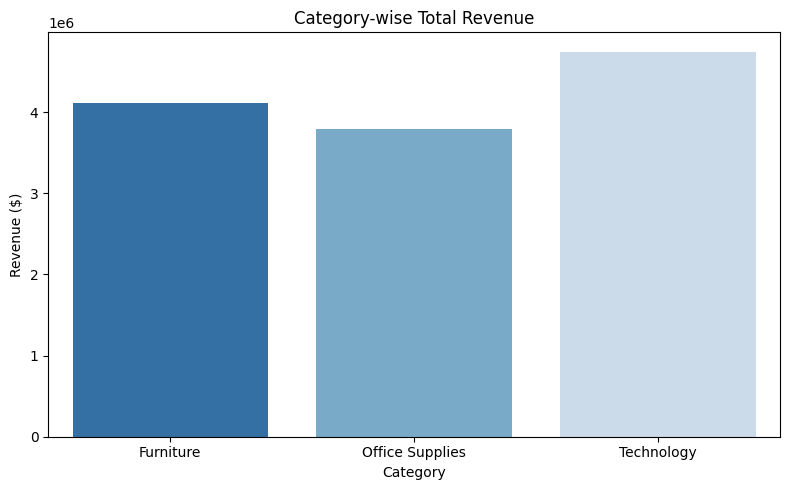

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

category_sales = df.groupby('Category')['Sales'].sum().reset_index()

plt.figure(figsize=(8, 5))
sns.barplot(
    data=category_sales, 
    x='Category', 
    y='Sales', 
    hue='Category',     
    palette='Blues_r', 
    legend=False         
)
plt.title('Category-wise Total Revenue')
plt.xlabel('Category')
plt.ylabel('Revenue ($)')
plt.tight_layout()
plt.show()